# GitHub Issue Triage Assistant | Week 9 live audit

Lohith Regalla (lr103) | RCEL 506 | 31 October 2026

This notebook reproduces the historical sample checks, chronological split, text model, and plots used in the local Streamlit demo. The saved sample is capped by label, and the newest test slice has only five Enhancements. Treat model results as a classroom proof of concept requiring maintainer review.

## 1. Shared data and modeling functions

The cell below contains the same functions as `triage.py` in the demo folder. It uses title and body as input. The target label and metadata are excluded from model features.

In [1]:
"""Reproducible, repository-specific issue triage prototype."""

from __future__ import annotations

import re
from dataclasses import dataclass
from pathlib import Path

import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.pipeline import Pipeline


LABELS = ("Bug", "Enhancement")
TARGET_WORDS = re.compile(
    r"\b(?:bug\s+reports?|new\s+features?|feature\s+requests?|bugs?|enhancements?|enh)\b",
    flags=re.IGNORECASE,
)
TEMPLATE_HEADERS = re.compile(r"(?m)^\s*#{1,6}\s+[^\n]*$")
SPACE = re.compile(r"\s+")


def clean_text(title: object, body: object) -> str:
    """Use only title and body, with explicit target words and common headers removed."""
    parts = [part if isinstance(part, str) else "" for part in (title, body)]
    text = "\n".join(parts)
    text = TEMPLATE_HEADERS.sub(" ", text)
    text = TARGET_WORDS.sub(" ", text)
    text = re.sub(r"(?m)^\s*[:;]\s*", " ", text)
    return SPACE.sub(" ", text).strip().lower()


def load_issues(path: Path) -> pd.DataFrame:
    issues = pd.read_csv(path)
    required = {"issue_number", "title", "body", "created_at", "issue_type"}
    missing = required - set(issues.columns)
    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")
    if issues["issue_number"].isna().any() or issues["issue_number"].duplicated().any():
        raise ValueError("Issue numbers must be present and unique")
    if issues["title"].isna().any():
        raise ValueError("Issue titles must be present")
    if set(issues["issue_type"]) != set(LABELS):
        raise ValueError("Expected exactly Bug and Enhancement labels")
    issues["created_at"] = pd.to_datetime(issues["created_at"], utc=True, errors="raise")
    issues["text"] = [clean_text(t, b) for t, b in zip(issues["title"], issues["body"])]
    if issues["text"].eq("").any():
        raise ValueError("One or more issues have no usable title or body text")
    return issues.sort_values(["created_at", "issue_number"]).reset_index(drop=True)


@dataclass
class Result:
    issues: pd.DataFrame
    train: pd.DataFrame
    test: pd.DataFrame
    model: Pipeline
    predictions: list[str]
    baseline_predictions: list[str]
    metrics: dict


def fit_and_evaluate(issues: pd.DataFrame) -> Result:
    """Fit text and majority models on the oldest 80% only."""
    if len(issues) < 20:
        raise ValueError("At least 20 issues are required")
    split = int(len(issues) * 0.8)
    train = issues.iloc[:split].copy()
    test = issues.iloc[split:].copy()
    if train["issue_type"].nunique() != 2 or test["issue_type"].nunique() != 2:
        raise ValueError("Both classes must be present in each split")
    model = Pipeline(
        [
            ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.95,
                                      max_features=30000, sublinear_tf=True)),
            ("logistic_regression", LogisticRegression(max_iter=1000, class_weight="balanced",
                                                       solver="liblinear")),
        ]
    )
    model.fit(train["text"], train["issue_type"])
    predictions = model.predict(test["text"]).tolist()
    baseline = DummyClassifier(strategy="most_frequent")
    baseline.fit([[0]] * len(train), train["issue_type"])
    baseline_predictions = baseline.predict([[0]] * len(test)).tolist()
    metrics = {
        "train_count": len(train),
        "test_count": len(test),
        "train_labels": train["issue_type"].value_counts().to_dict(),
        "test_labels": test["issue_type"].value_counts().to_dict(),
        "train_end": train["created_at"].max().isoformat(),
        "test_start": test["created_at"].min().isoformat(),
        "test_end": test["created_at"].max().isoformat(),
        "model": _scores(test["issue_type"], predictions),
        "baseline": _scores(test["issue_type"], baseline_predictions),
    }
    return Result(issues, train, test, model, predictions, baseline_predictions, metrics)


def _scores(actual: pd.Series, predicted: list[str]) -> dict:
    precision, recall, f1, support = precision_recall_fscore_support(
        actual, predicted, labels=LABELS, zero_division=0
    )
    return {
        "accuracy": round(float(accuracy_score(actual, predicted)), 4),
        "macro_f1": round(float(f1_score(actual, predicted, labels=LABELS,
                                         average="macro", zero_division=0)), 4),
        "per_class": {
            label: {"precision": round(float(precision[i]), 4),
                    "recall": round(float(recall[i]), 4),
                    "f1": round(float(f1[i]), 4),
                    "support": int(support[i])}
            for i, label in enumerate(LABELS)
        },
        "confusion_matrix": confusion_matrix(actual, predicted, labels=LABELS).tolist(),
    }


def predict_issue(result: Result, title: str, body: str) -> dict:
    text = clean_text(title, body)
    if len(text) < 10:
        raise ValueError("Enter a descriptive title or body with at least 10 usable characters")
    probabilities = result.model.predict_proba([text])[0]
    classes = result.model.classes_.tolist()
    return {
        "suggested_label": classes[int(probabilities.argmax())],
        "model_probabilities": {label: round(float(probabilities[classes.index(label)]), 3)
                                for label in LABELS},
    }


## 2. Load the saved data

If this notebook is opened alone in Colab, upload `scikit_learn_issues_bug_enhancement_sample.csv` when prompted. The same file is bundled in the project folder.

In [2]:
from pathlib import Path
import matplotlib.pyplot as plt

DATA_FILE = Path("data/scikit_learn_issues_bug_enhancement_sample.csv")
if not DATA_FILE.exists():
    DATA_FILE = Path("scikit_learn_issues_bug_enhancement_sample.csv")
if not DATA_FILE.exists():
    from google.colab import files
    uploaded = files.upload()
    DATA_FILE = Path("scikit_learn_issues_bug_enhancement_sample.csv")
    if DATA_FILE.name not in uploaded:
        raise FileNotFoundError("Upload the bundled CSV file")
issues = load_issues(DATA_FILE)
print("Rows:", len(issues))
print("Date range:", issues.created_at.min(), "to", issues.created_at.max())
print("Duplicate issue numbers:", issues.issue_number.duplicated().sum())
print("Missing bodies:", issues.body.isna().sum())
print(issues.issue_type.value_counts().to_string())
display(issues[["issue_number", "created_at", "issue_type", "title"]].head())

/Users/lohithregalla/.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /var/folders/gc/vqnkb2ms5jncfb797qmsjjv00000gn/T/matplotlib-btuz9c6x because there was an issue with the default path (/Users/lohithregalla/.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Matplotlib is building the font cache; this may take a moment.


Rows: 908
Date range: 2013-02-02 16:33:11+00:00 to 2026-08-26 20:42:40+00:00
Duplicate issue numbers: 0
Missing bodies: 1
issue_type
Bug            489
Enhancement    419


,issue_number,created_at,issue_type,title
0,1650,2013-02-02 16:33:11+00:00,Enhancement,Default value of 'normalize' inconsistent in l...
1,1652,2013-02-03 15:29:37+00:00,Enhancement,rename pairwise_distance_function to all upper...
2,1673,2013-02-10 20:26:31+00:00,Enhancement,AdaBoost is slow with ensemble of trees
3,1678,2013-02-13 20:05:37+00:00,Enhancement,Check consistency / correctness of 1d input an...
4,1687,2013-02-16 22:23:54+00:00,Enhancement,Make sure fit_transform(X) does the same as fi...


## 3. Check what the saved sample covers

These are counts in the saved sample, not annual totals for all scikit-learn issues.

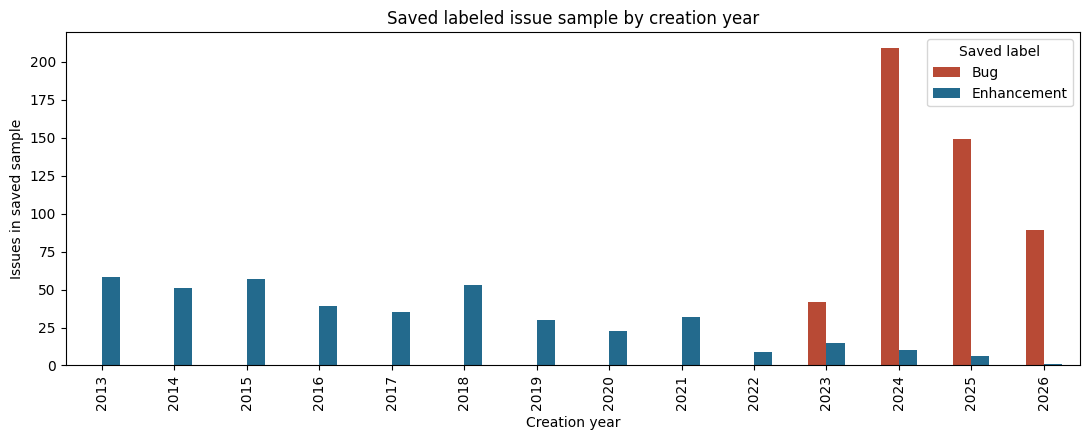

In [3]:
annual = (issues.assign(year=issues.created_at.dt.year)
          .groupby(["year", "issue_type"]).size().unstack(fill_value=0)
          .reindex(columns=LABELS, fill_value=0))
ax = annual.plot(kind="bar", figsize=(11, 4.5), color=["#B84A35", "#236A8D"])
ax.set(title="Saved labeled issue sample by creation year", xlabel="Creation year", ylabel="Issues in saved sample")
ax.legend(title="Saved label")
plt.tight_layout()
plt.show()

## 4. Train on older records and evaluate on newer records

TF-IDF is fit only on training text. The comparison model always predicts the training majority class.

In [4]:
result = fit_and_evaluate(issues)
print("Training:", result.metrics["train_count"], result.metrics["train_labels"])
print("Test:", result.metrics["test_count"], result.metrics["test_labels"])
print("Training end:", result.metrics["train_end"])
print("Test start:", result.metrics["test_start"])
print("Majority baseline:", result.metrics["baseline"]["accuracy"], "accuracy;", result.metrics["baseline"]["macro_f1"], "macro F1")
print("Text model:", result.metrics["model"]["accuracy"], "accuracy;", result.metrics["model"]["macro_f1"], "macro F1")
print("Per-class results:")
display(pd.DataFrame(result.metrics["model"]["per_class"]).T)

Training: 726 {'Enhancement': 414, 'Bug': 312}
Test: 182 {'Bug': 177, 'Enhancement': 5}
Training end: 2025-06-11T20:41:12+00:00
Test start: 2025-06-13T00:58:02+00:00
Majority baseline: 0.0275 accuracy; 0.0267 macro F1
Text model: 0.8462 accuracy; 0.5886 macro F1
Per-class results:


,precision,recall,f1,support
Bug,1.0000,0.8418,0.9141,177.0
Enhancement,0.1515,1.0000,0.2632,5.0


## 5. Inspect errors

Rows are actual labels and columns are predicted labels. The five Enhancement test cases make the estimated performance unstable.

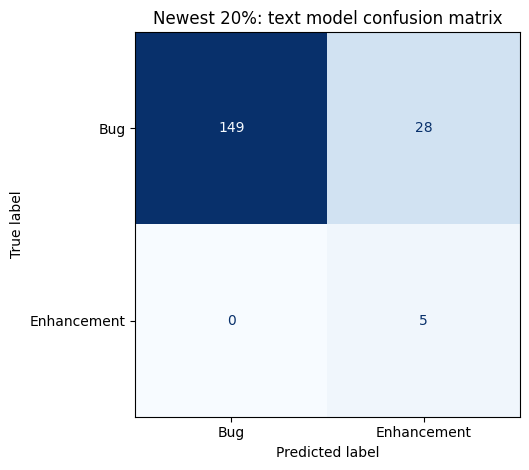

Misclassified issues: 28


,issue_number,created_at,issue_type,title,suggested_label
739,31776,2025-07-17 14:02:05+00:00,Bug,"Documentation Bug: Warning about ""unstable dev...",Enhancement
745,31872,2025-08-03 21:59:31+00:00,Bug,Strange normalization of semi-supervised label...,Enhancement
746,31885,2025-08-06 15:37:02+00:00,Bug,`SVC(probability=True)` is not thread-safe,Enhancement
775,32276,2025-09-25 21:30:22+00:00,Bug,Fix the pip name,Enhancement
776,32279,2025-09-26 11:54:04+00:00,Bug,Wheels CI hang with macOS x86_64 (aka Intel) w...,Enhancement
779,32292,2025-09-28 18:19:54+00:00,Bug,scikit-learn crash silently on Window11 with c...,Enhancement
782,32355,2025-10-03 10:06:16+00:00,Bug,Dark visual studio theme seems to mix fitted a...,Enhancement
795,32691,2025-11-11 07:47:46+00:00,Bug,Memory Leak in Logistic Regression.,Enhancement
800,32725,2025-11-17 07:37:52+00:00,Bug,Random-seed-dependent test failures in `macOS ...,Enhancement
801,32748,2025-11-20 06:19:32+00:00,Bug,LogisticRegressionCV bug when one fold has not...,Enhancement


In [5]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(result.test.issue_type, result.predictions, labels=LABELS, cmap="Blues", colorbar=False)
plt.title("Newest 20%: text model confusion matrix")
plt.tight_layout()
plt.show()
errors = result.test.loc[result.test.issue_type.to_numpy() != result.predictions, ["issue_number", "created_at", "issue_type", "title"]].copy()
errors["suggested_label"] = [p for a, p in zip(result.test.issue_type, result.predictions) if a != p]
print("Misclassified issues:", len(errors))
display(errors.head(10))

## 6. Try a new issue

Edit the two text fields and rerun this cell. The suggestion is preliminary, and the probability is not a calibrated reliability estimate.

In [6]:
title = "Pipeline fails when input contains missing values"
body = "The fit method raises an exception when a column has NaN values. I expected a clear validation message."
print(predict_issue(result, title, body))

{'suggested_label': 'Enhancement', 'model_probabilities': {'Bug': 0.357, 'Enhancement': 0.643}}


## Decision for the CTO

The prototype is reproducible and interactive. It does not establish useful performance on incoming issues. Before deployment, approve the target mapping, collect a creation-date cohort without label caps, preserve label history, and test on a recent set with enough examples of both classes.